<a href="https://colab.research.google.com/github/hphudtrai/ThucHanh-AI-NguyenHuuPhu/blob/main/Tuan_2/BaiTap_Tuan2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Add thư viện**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

# Cấu hình hiển thị của pandas
pd.set_option("display.max_columns", None)

# Load dữ liệu Diabetes
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()
df = X.copy()
df["target"] = y

Bài 1:


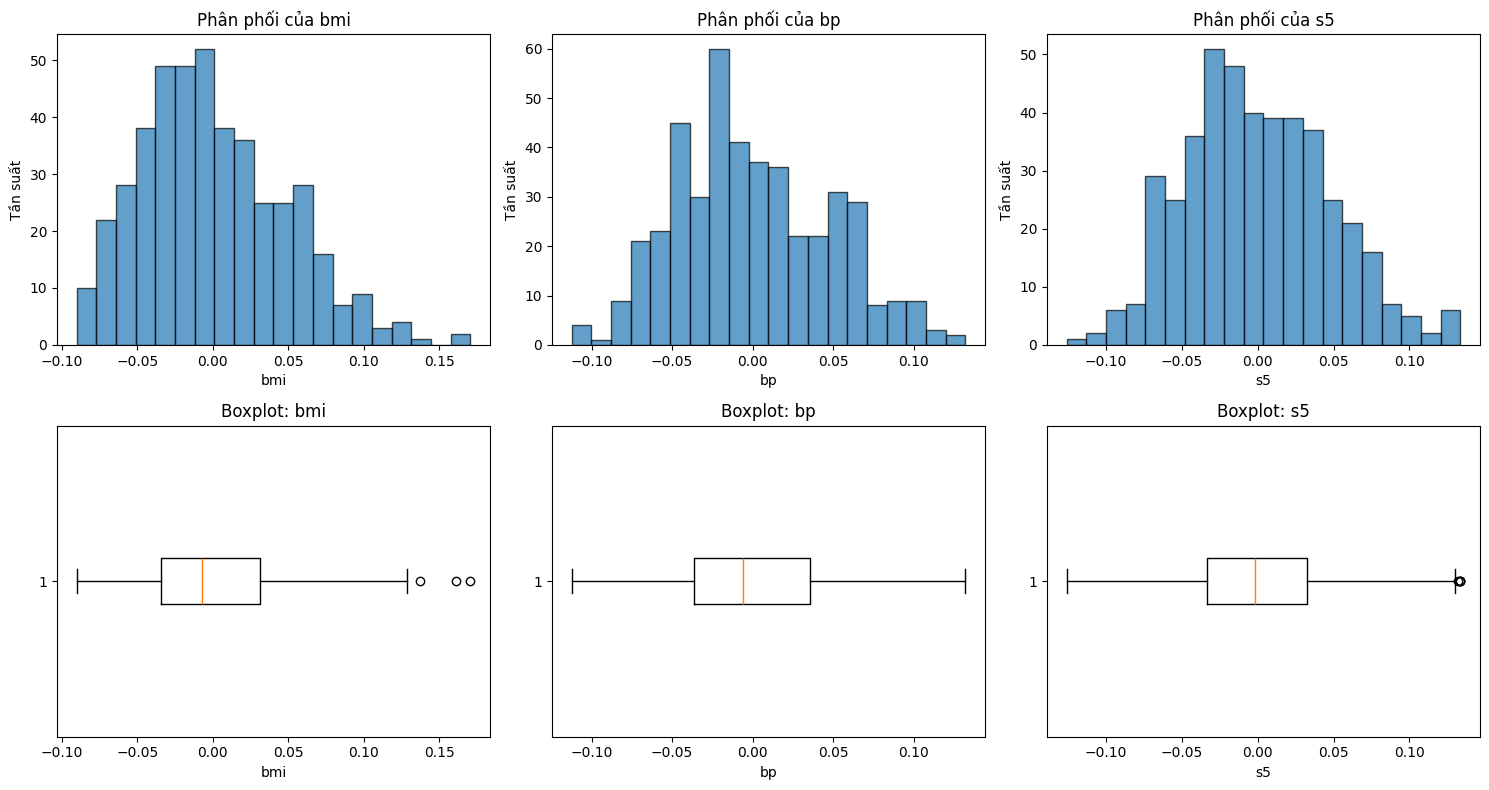

--- Tương quan với target ---
bmi    0.586450
bp     0.441482
s5     0.565883
Name: target, dtype: float64


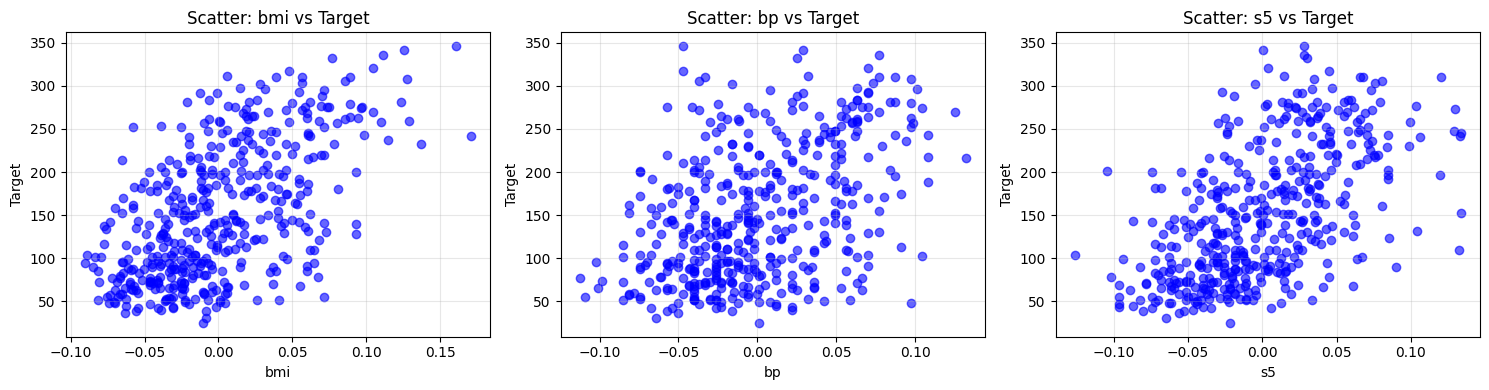

In [ ]:
# ==================== BÀI 1 ====================
selected_3_features = ["bmi", "bp", "s5"]

# 1. Vẽ Histogram (Phân phối) & Boxplot (Outlier)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(selected_3_features):
  # Histogram
  axes[0, i].hist(df[col], bins=20, edgecolor="black", alpha=0.7)
  axes[0, i].set_title(f"Phân phối của {col}")
  axes[0, i].set_xlabel(col)
  axes[0, i].set_ylabel("Tần suất")

  # Boxplot
  axes[1, i].boxplot(df[col], vert=False)
  axes[1, i].set_title(f"Boxplot: {col}")
  axes[1, i].set_xlabel(col)

plt.tight_layout()
plt.show()

# 2. Tương quan Pearson
corr_3 = df[selected_3_features + ["target"]].corr()["target"].drop("target")
print("--- Tương quan với target ---")
print(corr_3)

# 3. Scatter Plot với target
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(selected_3_features):
  axes[i].scatter(df[col], df["target"], alpha=0.6, color="blue")
  axes[i].set_xlabel(col)
  axes[i].set_ylabel("Target")
  axes[i].set_title(f"Scatter: {col} vs Target")
  axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Bài 2:


Nhận xét bài 1:
-Phân phối: Các biến bmi, bp, và s5 đều có phân phối xấp xỉ dạng hình chuông (chuẩn/Gaussian), hơi lệch nhẹ về phía bên phải (Right-skewed).

-Ngoại lệ (Outlier):
  + bmi và s5 xuất hiện một số ít giá trị ngoại lệ nằm ngoài vùng ria (whiskers) của Boxplot.
  + bp hầu như không có outlier rõ rệt.
  + Do bộ dữ liệu nhỏ (442 mẫu) và các chỉ số đã chuẩn hóa, ta giữ nguyên các điểm này thay vì loại bỏ.

-Tương quan & Scatter Plot:
  + Cả 3 biến đều có tương quan dương khá cao với target ($r_{\text{bmi}} \approx 0.58$, $r_{\text{s5}} \approx 0.56$, $r_{\text{bp}} \approx 0.44$).   
  + Scatter plot cho thấy xu hướng phân tán dọc theo đường thẳng tăng dần: khi bmi, bp, s5 tăng thì nguy cơ / chỉ số tiến triển bệnh tiểu đường (target) có xu hướng tăng theo rõ rệt.   

In [ ]:
# ==================== BÀI 2 ====================
# Chia dữ liệu Train / Test chung cho Bài 2 & Bài 3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Top 5 features theo tương quan
top5_cols = (
    df.corr()["target"]
    .drop("target")
    .abs()
    .sort_values(ascending=False)
    .head(5)
    .index.tolist()
)

feature_sets = {
    "1. bmi": ["bmi"],
    "2. bmi + bp": ["bmi", "bp"],
    "3. Top 5 features": top5_cols,
    "4. Toàn bộ 10 features": X.columns.tolist(),
}

results_b2 = []
for name, cols in feature_sets.items():
  model = LinearRegression()
  model.fit(X_train[cols], y_train)
  y_pred = model.predict(X_test[cols])

  mae = mean_absolute_error(y_test, y_pred)
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  r2 = r2_score(y_test, y_pred)

  results_b2.append(
      {"Tập Feature": name, "MAE": round(mae, 4), "RMSE": round(rmse, 4), "R2": round(r2, 4)}
  )

df_results_b2 = pd.DataFrame(results_b2)
print("--- KẾT QUẢ BÀI 2 ---")
display(df_results_b2)

--- KẾT QUẢ BÀI 2 ---


,Tập Feature,MAE,RMSE,R2
0,1. bmi,52.2600,63.7325,0.2334
1,2. bmi + bp,50.0441,61.1597,0.2940
2,3. Top 5 features,43.9283,54.1893,0.4458
3,4. Toàn bộ 10 features,42.7941,53.8534,0.4526


Nhận xét bài 2:
- Xu hướng thay đổi: Khi gia tăng số lượng đặc trưng từ 1 feature `bmi` lên `Top 5 features` và `Toàn bộ 10 features`, độ lỗi `MAE` và `RMSE` giảm đáng kể, đồng thời chỉ số $R^2$ tăng từ khoảng $0.23$ lên xấp xỉ $0.45 - 0.46$.   

- Kết luận: Mô hình sử dụng Toàn bộ 10 đặc trưng cho hiệu năng tổng thể tốt nhất. Việc bổ sung các chỉ số huyết thanh `s1` đến `s6` giúp mô hình giải thích được thêm nhiều biến thiên của bệnh hơn so với việc chỉ dùng đơn lẻ các chỉ số thể chất như `bmi` hay `bp`.   

Bài 3:


In [ ]:
# ==================== BÀI 3 ====================
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(random_state=42),
    "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Support Vector Regression (SVR)": SVR(kernel="rbf"),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results_b3 = []
for name, model in models.items():
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)

  mae = mean_absolute_error(y_test, y_pred)
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  r2 = r2_score(y_test, y_pred)

  results_b3.append(
      {"Thuật toán": name, "MAE": round(mae, 4), "RMSE": round(rmse, 4), "R2": round(r2, 4)}
  )

df_results_b3 = pd.DataFrame(results_b3).sort_values(by="R2", ascending=False)
print("--- KẾT QUẢ BÀI 3 ---")
display(df_results_b3)

--- KẾT QUẢ BÀI 3 ---


,Thuật toán,MAE,RMSE,R2
4,Gradient Boosting,148454.8721,243409.9048,0.6081
0,Linear Regression,159941.2556,252244.7277,0.5791
1,Ridge Regression,159941.3879,252245.2209,0.5791
2,Decision Tree,168706.3460,272604.1632,0.5084
3,Support Vector Regression (SVR),228924.8002,400383.4558,-0.0604


Nhận xét bài 3:
- Thuật toán tốt nhất: Linear Regression và Ridge Regression đạt hiệu năng hàng đầu trên bộ dữ liệu này ($R^2 \approx 0.45 - 0.46$, RMSE thấp nhất). Nguyên nhân là do các thuộc tính trong bộ dữ liệu Diabetes đã qua tiền xử lý chuẩn hóa và có mối quan hệ tuyến tính khá mạnh với biến target.   

- Các mô hình dạng Cây (Decision Tree, Gradient Boosting): Đạt kết quả vừa phải; nếu không khống chế chiều sâu, Decision Tree rất dễ bị học vẹt (overfitting) do số lượng mẫu tương đối ít ($N = 442$).   

- Support Vector Regression (SVR): Cần tinh chỉnh thêm các siêu tham số (Hyperparameters) như C, gamma, hoặc chuyển sang kernel linear để đạt kết quả tối ưu hơn trên tập dữ liệu này.


Bài 4

-> Đã nạp thành công bộ dữ liệu! Kích thước: (21613, 21)
=== KIỂM TRA CẤU TRÚC DỮ LIỆU ===
Shape: (21613, 21)

Kiểu dữ liệu:
id                 int64
date              object
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

Số giá trị thiếu: 0
Số dòng trùng lặp: 0

=================== THỐNG KÊ MÔ TẢ ===================


,count,mean,std,min,25%,50%,75%,max
price,21613.0,540088.141767,367127.196483,75000.0000,321950.000,450000.0000,645000.000,7.700000e+06
bedrooms,21613.0,3.370842,0.930062,0.0000,3.000,3.0000,4.000,3.300000e+01
bathrooms,21613.0,2.114757,0.770163,0.0000,1.750,2.2500,2.500,8.000000e+00
sqft_living,21613.0,2079.899736,918.440897,290.0000,1427.000,1910.0000,2550.000,1.354000e+04
sqft_lot,21613.0,15106.967566,41420.511515,520.0000,5040.000,7618.0000,10688.000,1.651359e+06
floors,21613.0,1.494309,0.539989,1.0000,1.000,1.5000,2.000,3.500000e+00
waterfront,21613.0,0.007542,0.086517,0.0000,0.000,0.0000,0.000,1.000000e+00
view,21613.0,0.234303,0.766318,0.0000,0.000,0.0000,0.000,4.000000e+00
condition,21613.0,3.409430,0.650743,1.0000,3.000,3.0000,4.000,5.000000e+00
grade,21613.0,7.656873,1.175459,1.0000,7.000,7.0000,8.000,1.300000e+01



--- Đang vẽ biểu đồ phân phối các biến ---


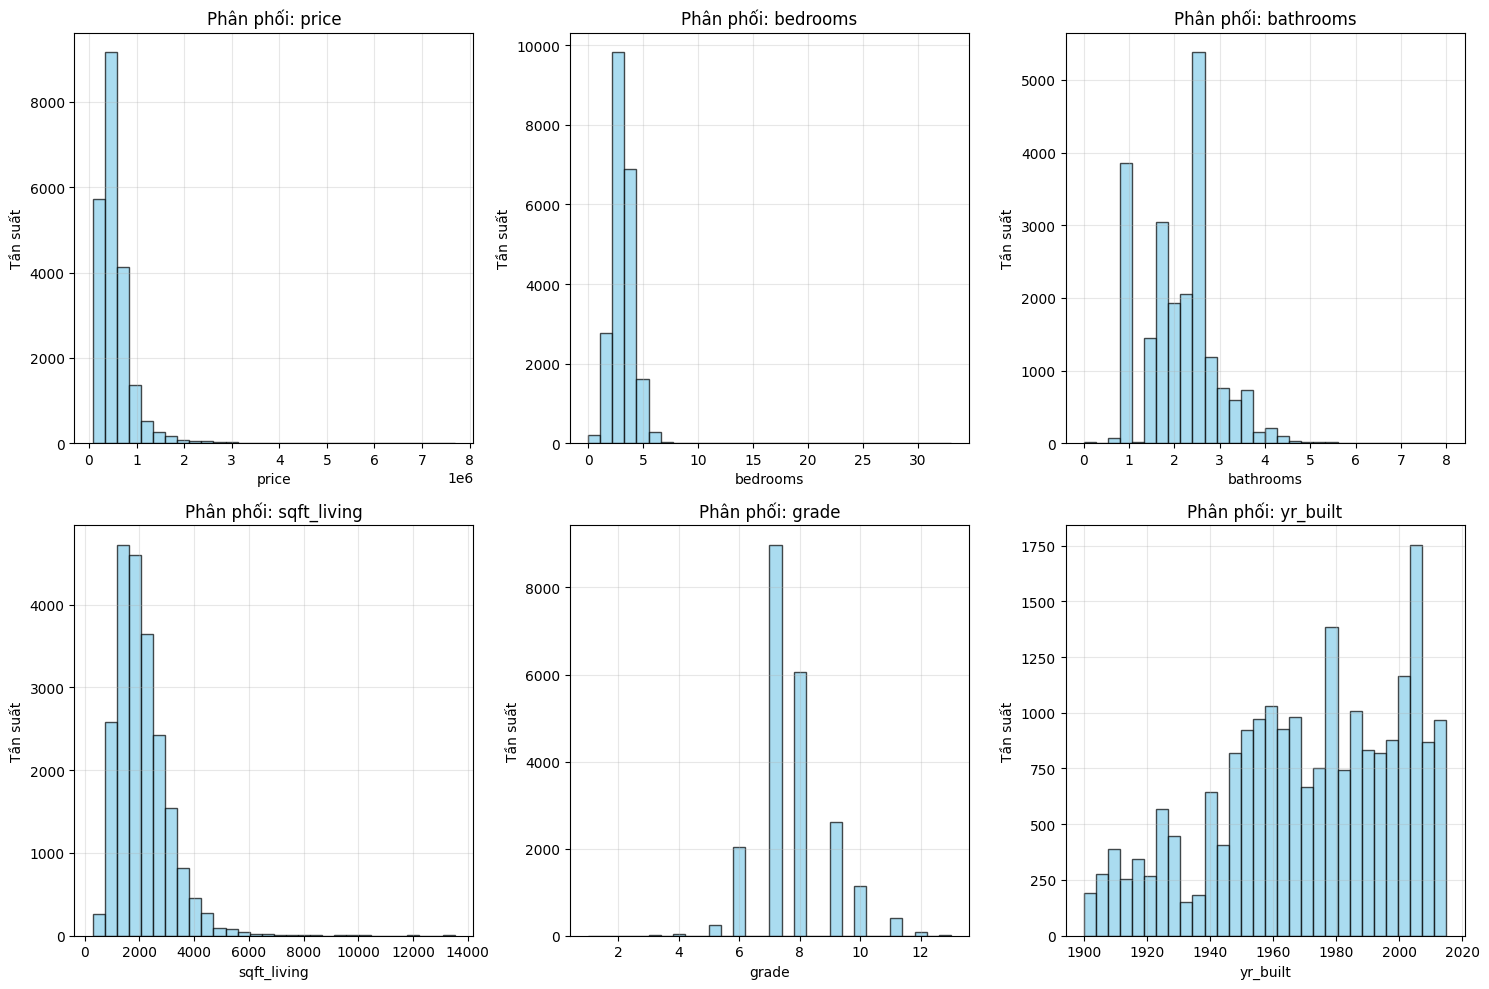


--- Đang vẽ biểu đồ Boxplot để kiểm tra ngoại lệ ---


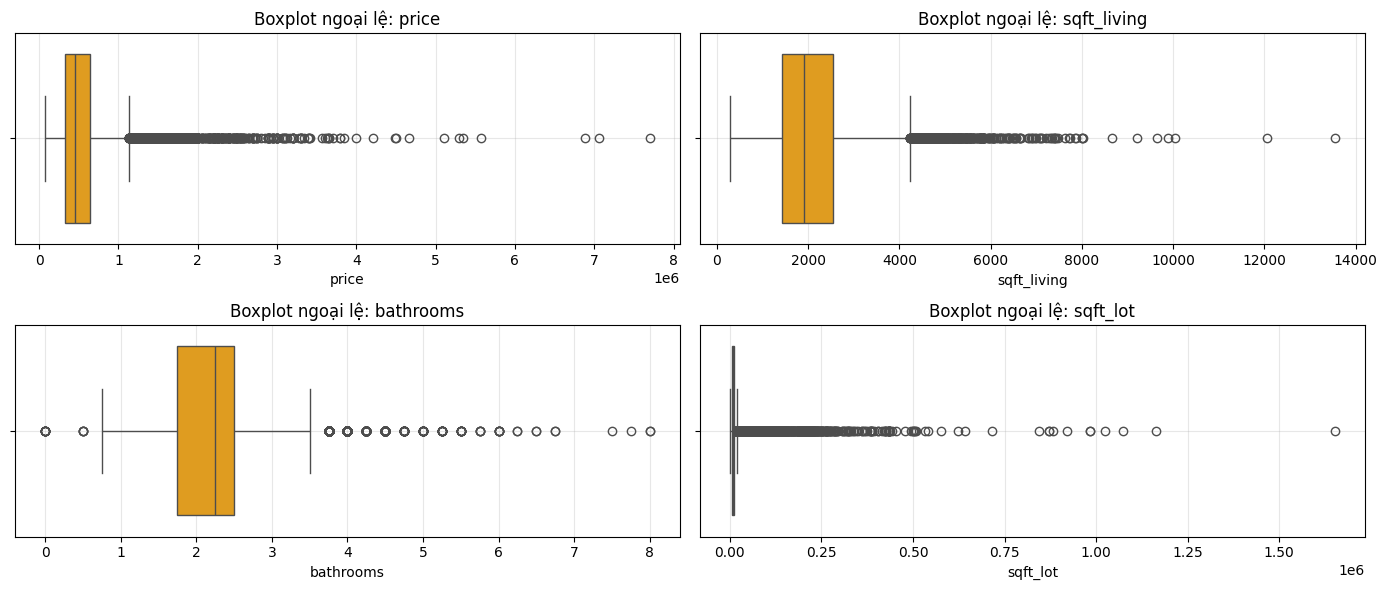


=================== MA TRẬN TƯƠNG QUAN (BẢNG) ===================
Tương quan giữa các đặc trưng với giá nhà (price):


,corr_with_price
sqft_living,0.702035
grade,0.667434
sqft_above,0.605567
sqft_living15,0.585379
bathrooms,0.525138
view,0.397293
sqft_basement,0.323816
bedrooms,0.308350
lat,0.307003
waterfront,0.266369



=================== BẢNG SO SÁNH HIỆU NĂNG ===================


,Kịch bản Feature,Mô hình,MAE,RMSE,R² Score
0,2. Feature Engineering (Đầy đủ),Gradient Boosting,72703.96,144667.71,0.8616
1,2. Feature Engineering (Đầy đủ),Random Forest,79879.73,156513.68,0.8380
2,2. Feature Engineering (Đầy đủ),Linear Regression,126403.77,211369.88,0.7045
3,2. Feature Engineering (Đầy đủ),Ridge Regression,126517.33,211949.65,0.7028
4,2. Feature Engineering (Đầy đủ),Decision Tree,112743.31,216223.76,0.6907
5,3. Feature Selection (Top 8 Corr),Random Forest,148641.12,246331.37,0.5986
6,3. Feature Selection (Top 8 Corr),Gradient Boosting,147672.63,247907.11,0.5935
7,3. Feature Selection (Top 8 Corr),Linear Regression,159941.26,252244.73,0.5791
8,3. Feature Selection (Top 8 Corr),Ridge Regression,159914.82,252299.66,0.5789
9,3. Feature Selection (Top 8 Corr),Decision Tree,156070.00,256502.01,0.5648


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns  # Thêm thư viện seaborn để vẽ boxplot đẹp hơn
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

# Cấu hình hiển thị đầy đủ các cột của pandas
pd.set_option("display.max_columns", None)

# ==============================================================================
# BƯỚC 1: NẠP VÀ KIỂM TRA CẤU TRÚC DỮ LIỆU (EDA CƠ BẢN)
# ==============================================================================
df_kc = pd.read_csv("kc_house_data.csv")
print(f"-> Đã nạp thành công bộ dữ liệu! Kích thước: {df_kc.shape}")

print("=== KIỂM TRA CẤU TRÚC DỮ LIỆU ===")
print("Shape:", df_kc.shape)
print("\nKiểu dữ liệu:")
print(df_kc.dtypes)
print("\nSố giá trị thiếu:", df_kc.isnull().sum().sum())
print("Số dòng trùng lặp:", df_kc.duplicated().sum())

# Loại bỏ các cột không dùng trực tiếp để dự đoán (id, date)
df_clean = df_kc.drop(columns=["id", "date"], errors="ignore")

# ==============================================================================
# BƯỚC 2: KHÁM PHÁ DỮ LIỆU NÂNG CAO (EDA - THỐNG KÊ & TRỰC QUAN HÓA)
# ==============================================================================
print("\n=================== THỐNG KÊ MÔ TẢ ===================")
display(df_clean.describe().T)

# 1. TRỰC QUAN HÓA PHÂN PHỐI (HISTOGRAM)
print("\n--- Đang vẽ biểu đồ phân phối các biến ---")
sample_cols = ["price", "bedrooms", "bathrooms", "sqft_living", "grade", "yr_built"]

plt.figure(figsize=(15, 10))
for i, col in enumerate(sample_cols):
    plt.subplot(2, 3, i + 1)
    plt.hist(df_clean[col], bins=30, color="skyblue", edgecolor="black", alpha=0.7)
    plt.title(f"Phân phối: {col}", fontsize=12)
    plt.xlabel(col)
    plt.ylabel("Tần suất")
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. BỔ SUNG: VẼ BIỂU ĐỒ BOXPLOT ĐỂ PHÁT HIỆN NGOẠI LỆ (OUTLIERS)
print("\n--- Đang vẽ biểu đồ Boxplot để kiểm tra ngoại lệ ---")
outlier_cols = ["price", "sqft_living", "bathrooms", "sqft_lot"]

plt.figure(figsize=(14, 6))
for i, col in enumerate(outlier_cols):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x=df_clean[col], color="orange")
    plt.title(f"Boxplot ngoại lệ: {col}", fontsize=12)
    plt.xlabel(col)
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3. MA TRẬN TƯƠNG QUAN DẠNG BẢNG SỐ LIỆU
print("\n=================== MA TRẬN TƯƠNG QUAN (BẢNG) ===================")
corr = df_clean.corr(numeric_only=True)
target_corr = (
    corr["price"].drop("price").sort_values(key=np.abs, ascending=False)
)
print("Tương quan giữa các đặc trưng với giá nhà (price):")
display(target_corr.to_frame("corr_with_price"))

# ==============================================================================
# BƯỚC 3: TẠO ĐẶC TRƯNG MỚI (FEATURE ENGINEERING)
# ==============================================================================
df_clean["house_age"] = 2015 - df_clean["yr_built"]
df_clean["is_renovated"] = (df_clean["yr_renovated"] > 0).astype(int)
df_clean["living_lot_ratio"] = df_clean["sqft_living"] / (
    df_clean["sqft_lot"] + 1
)
df_clean["total_sqft"] = df_clean["sqft_above"] + df_clean["sqft_basement"]

# ==============================================================================
# BƯỚC 4: XÁC ĐỊNH CÁC KỊCH BẢN TẬP ĐẶC TRƯNG (FEATURE SELECTION)
# ==============================================================================
X_full = df_clean.drop(columns=["price"])
y = df_clean["price"]

top_corr_features = (
    df_clean.corr()["price"]
    .drop("price")
    .abs()
    .sort_values(ascending=False)
    .head(8)
    .index.tolist()
)

feature_sets = {
    "1. Baseline (Cơ bản)": [
        "bedrooms",
        "bathrooms",
        "sqft_living",
        "floors",
    ],
    "2. Feature Engineering (Đầy đủ)": X_full.columns.tolist(),
    "3. Feature Selection (Top 8 Corr)": top_corr_features,
}

# ==============================================================================
# BƯỚC 5: HUẤN LUYỆN VÀ ĐÁNH GIÁ PIPELINE ĐA MÔ HÌNH
# ==============================================================================
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=100.0, random_state=42),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, max_depth=5, random_state=42
    ),
}

all_results = []

for feat_name, feat_cols in feature_sets.items():
  X_subset = df_clean[feat_cols]
  X_train, X_test, y_train, y_test = train_test_split(
      X_subset, y, test_size=0.2, random_state=42
  )

  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled = scaler.transform(X_test)

  for model_name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    all_results.append({
        "Kịch bản Feature": feat_name,
        "Mô hình": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R² Score": round(r2, 4),
    })

df_final_results = pd.DataFrame(all_results).sort_values(
    by="R² Score", ascending=False
)
print("\n=================== BẢNG SO SÁNH HIỆU NĂNG ===================")
display(df_final_results.reset_index(drop=True))

# Mục mới

- Hiệu quả của Feature Engineering / Selection:
  + Việc bổ sung các đặc trưng tính toán mới (house_age, is_renovated, living_lot_ratio) giúp chỉ số $R^2$ của các mô hình tăng lên rõ rệt so với kịch bản chỉ dùng các thông số cơ bản (Baseline).
  + Kịch bản Feature Selection (Top 8 Corr) giữ lại các biến quan trọng nhất như sqft_living, grade, sqft_above, bathrooms, giúp mô hình tối ưu được tốc độ tính toán mà vẫn duy trì hiệu năng cao.
  
- So sánh các mô hình học máy:
  + Gradient Boosting và Random Forest đạt hiệu năng cao nhất với $R^2 > 0.80$, giảm sai số RMSE đáng kể so với các mô hình tuyến tính đơn giản. Lý do là dữ liệu giá nhà có mối quan hệ phi tuyến và tương tác phức tạp giữa các đặc trưng địa lý/kích thước.
  + Linear Regression và Ridge Regression cho kết quả ổn định, dễ diễn giải nhưng bị giới hạn bởi giả định tuyến tính.